annual_income 0.608
number_of_courses_viewed 0.723
interaction_count 0.765
lead_score 0.788
0.732


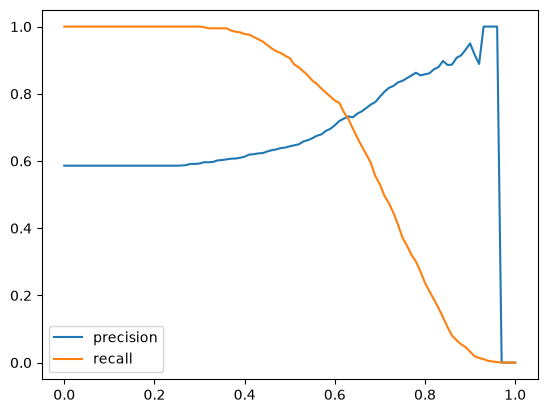

0.63
0.41
0.007
1e-06 0.617 0.019
0.001 0.749 0.01
1 0.732 0.007


In [19]:
# %%
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score


# %%
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

target = 'converted'
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)


# %%
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

y_train = df_train[target].values
y_val = df_val[target].values


# %%
def train(df, y, C=1.0):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df[categorical + numerical].to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y)
    return dv, model


def predict(df, dv, model):
    X = dv.transform(df[categorical + numerical].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]


# %%
# Q1
for c in numerical:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
    print(c, round(auc, 3))


# %%
# Q2
dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)

print(round(roc_auc_score(y_val, y_pred), 3))


# %%
# Q3
def precision_recall(y, y_pred, t):
    tp = ((y_pred >= t) & (y == 1)).sum()
    fp = ((y_pred >= t) & (y == 0)).sum()
    fn = ((y_pred < t) & (y == 1)).sum()
    p = tp / (tp + fp) if tp + fp > 0 else 0.0
    r = tp / (tp + fn) if tp + fn > 0 else 0.0
    return p, r


thresholds = np.round(np.arange(0.0, 1.01, 0.01), 2)
scores = pd.DataFrame(
    [(t, *precision_recall(y_val, y_pred, t)) for t in thresholds],
    columns=['threshold', 'precision', 'recall'],
)


# %%
plt.plot(scores.threshold, scores.precision, label='precision')
plt.plot(scores.threshold, scores.recall, label='recall')
plt.legend()
plt.show()


# %%
s = scores[(scores.precision > 0) | (scores.recall > 0)]
diff = (s.precision - s.recall).abs()

print(s.threshold[diff.idxmin()])


# %%
# Q4
p, r = scores.precision, scores.recall
scores['f1'] = 2 * p * r / (p + r)

print(scores.threshold[scores.f1.idxmax()])


# %%
# Q5
def cv_auc(C=1.0):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    aucs = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]
        dv, model = train(df_tr, df_tr[target].values, C=C)
        y_pred = predict(df_va, dv, model)
        aucs.append(roc_auc_score(df_va[target].values, y_pred))
    return np.array(aucs)


aucs = cv_auc(C=1.0)
print(round(aucs.std(), 3))


# %%
# Q6
for C in [0.000001, 0.001, 1]:
    aucs = cv_auc(C=C)
    print(C, round(aucs.mean(), 3), round(aucs.std(), 3))
